# Discharge Outcome Prediction — Post-Treatment Support for Doctors
---

## The question this answers

A doctor who has already treated a road-accident patient wants a second check on the likely
outcome before finalising discharge.

> **Will this patient achieve complete recovery, partial recovery, or need further
> interventions?**

Unlike the severity model (arrival-time only), this model runs **after treatment** — so
length of stay, transfer, investigations and management given are all legitimate inputs, because
the doctor already knows them at the point of asking.

---

## Design commitments — same standards as the severity model

| Commitment | How it is enforced |
|---|---|
| Only post-treatment-appropriate information | Every candidate column audited in Section 3 |
| Honest performance estimate | Three-way split; holdout opened once (Section 15) |
| Decisions derived, not assumed | Feature set, class weights, and confidence layer all measured on validation |
| No sensitive attributes | Sex and ethnicity excluded from all features |
| Explanations grounded in the model | Permutation importance on holdout, not SHAP |

Class imbalance here is severe — partial recovery is the overwhelming majority class, and
**further interventions is the class that matters clinically** (missing it means a patient is
discharged when they should have been escalated) while being the rarest (~5%). The whole
pipeline is built around protecting recall on that one class without pretending it's easy.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight

# Tree-native classifiers - not part of scikit-learn:
#   pip install catboost xgboost lightgbm
from catboost import CatBoostClassifier
import xgboost as xgb
import lightgbm as lgb

import joblib

RANDOM_STATE = 42
DATA_PATH = "Preprocessed_Dataset.csv"
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SEARCH_CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.random.seed(RANDOM_STATE)
print("Setup complete.")

Setup complete.


## 2. Load and normalise

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded {df_raw.shape[0]:,} patient records x {df_raw.shape[1]} columns")

df = df_raw.copy()
for c in df.columns:
    if df[c].dtype == object or str(df[c].dtype) == "str":
        df[c] = (df[c].astype(str).str.strip().str.lower()
                 .replace({"nan": np.nan, "none": np.nan, "": np.nan}))
df = df.rename(columns={"Collision With ": "Collision With"})
print("Text columns normalised.")

Loaded 6,178 patient records x 130 columns
Text columns normalised.


## 3. Eligibility audit — the post-treatment contract

The rule here is different from the severity model's arrival-time contract, because this model
runs **after** treatment: anything the doctor already knows at the point of discharge decision is
fair game, including length of stay, transfer history, investigations, and management given.

What's still excluded:

| Class | Meaning |
|---|---|
| `TARGET` | `Discharge Outcome` itself |
| `ADMIN` | Hospital/record identity, dates |
| `EXCLUDED_ETHICAL` | Sensitive attributes and socioeconomic fields |
| `BOOKKEEPING` | Auto-generated `_missing_reason` columns |
| `POST_ARRIVAL_ELIGIBLE` | Everything else — legitimate for this model |

An assertion enforces every column is classified.

In [3]:
TARGET_COL = ["Discharge Outcome"]

ADMIN = ["Current Hospital Name", "First Hospital Name", "Incident At Time and Date",
         "Date Of Birth"]

EXCLUDED_ETHICAL = [
    "Bystander Expenditure per day", "Traveling Expenditure per day",
    "Total Traveling Expenditure For Whole Hospital Stay",
    "Family Monthly Income Before Accident", "Family Monthly Income After Accident",
    "Family Current Status", "Hospital Distance From Home", "Any Insurance Claim Type",
    "Any Other Hospital Admission Expenditure", "Vehicle Insured", "Vehicle Insurance Type",
    "Occupation", "Employment Type Name", "Educational Qualification", "Life Style",
    "Dress Name",
]

BOOKKEEPING = [c for c in df.columns if c.endswith("_missing_reason")]

_assigned = set(TARGET_COL) | set(ADMIN) | set(EXCLUDED_ETHICAL) | set(BOOKKEEPING)
POST_ARRIVAL_ELIGIBLE = [c for c in df.columns if c not in _assigned]

audit = pd.Series(
    {**{c: "TARGET" for c in TARGET_COL},
     **{c: "ADMIN" for c in ADMIN},
     **{c: "EXCLUDED_ETHICAL" for c in EXCLUDED_ETHICAL},
     **{c: "BOOKKEEPING" for c in BOOKKEEPING},
     **{c: "POST_ARRIVAL_ELIGIBLE" for c in POST_ARRIVAL_ELIGIBLE}}
).reindex(df.columns)

assert audit.notna().all(), f"Unclassified: {list(audit[audit.isna()].index)}"
print(audit.value_counts().to_string())
print(f"\nAll {len(audit)} columns classified.")

BOOKKEEPING              65
POST_ARRIVAL_ELIGIBLE    44
EXCLUDED_ETHICAL         16
ADMIN                     4
TARGET                    1

All 130 columns classified.


## 4. Target and candidate features

`Discharge Outcome` has one `others` row with no usable ground truth for a 3-class classifier —
dropped, same principle as any target-undefined row.

Candidate features are a hand-picked subset of `POST_ARRIVAL_ELIGIBLE` — chosen for clinical
relevance to a discharge decision, not the full 90+ column list. Being *eligible* under Section 3
doesn't mean every eligible column belongs here; e.g. `Type of Toilet Modification` is arrival-
irrelevant admin noise for this specific question.

In [4]:
df = df[df["Discharge Outcome"] != "others"].copy()

CANDIDATE_FEATURES = [
    # demographics
    "Age",
    # accident circumstances
    "Mode of Transport to the Hospital", "Time Taken To Reach Hospital", "Vehicle Type",
    "Helmet Worn", "Collision With", "Approximate Speed", "Road Type", "Road Condition",
    "Visiblity", "Road Signals Exist", "Collision Force From", "Alcohol Consumption",
    "Illicit Drugs",
    # injury detail
    "Site of Injury No1", "Type of injury No 1", "Site of injury No 2", "Type of Injury No 2",
    # length of stay
    "Number of days in first ward", "Number of days in Second ward",
    "Number of days in Third ward",
    # escalation of care
    "Transfer To Next Hospital", "Treatment During Tranfer", "State of Transfer",
    # treatment given
    "Investigation Done", "Management Name 1", "Management Name 2",
]

missing_from_data = [c for c in CANDIDATE_FEATURES if c not in df.columns]
assert not missing_from_data, f"Candidate features not in data: {missing_from_data}"
outside_eligible = [c for c in CANDIDATE_FEATURES if c not in POST_ARRIVAL_ELIGIBLE]
assert not outside_eligible, f"Candidate features outside the eligible set: {outside_eligible}"

print(f"{len(CANDIDATE_FEATURES)} candidate features, all confirmed eligible.")
print(f"\nTarget distribution:\n{df['Discharge Outcome'].value_counts()}")
print(f"\nTarget distribution (share):\n{df['Discharge Outcome'].value_counts(normalize=True).round(3)}")

27 candidate features, all confirmed eligible.

Target distribution:
Discharge Outcome
partial recovery         5314
complete recovery         545
further interventions     318
Name: count, dtype: int64

Target distribution (share):
Discharge Outcome
partial recovery         0.860
complete recovery        0.088
further interventions    0.051
Name: proportion, dtype: float64


## 5. Feature engineering

Three ward-day columns collapse into one `total_days`. `early_discharge` blanks are filled with
0, same reasoning as the severity model — "discharged early" and "unknown" are different facts.

`Number of Wards Stayed` is dropped as a separate feature: it correlates 0.60 with `total_days`,
carrying largely the same signal under a different unit. Keeping both would let the model
double-count length of stay rather than genuinely learning from two independent facts.

In [5]:
ward_cols = ["Number of days in first ward", "Number of days in Second ward",
             "Number of days in Third ward"]
for c in ward_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    early = df[f"{c}_missing_reason"] == "early_discharge"
    df.loc[early, c] = df.loc[early, c].fillna(0)

df["total_days"] = df[ward_cols].sum(axis=1, min_count=1)

CANDIDATE_FEATURES = [c for c in CANDIDATE_FEATURES if c not in ward_cols] + ["total_days"]
print(f"Missing total_days: {df['total_days'].isna().mean():.1%}")
print(f"Candidate features now: {len(CANDIDATE_FEATURES)}")

Missing total_days: 0.0%
Candidate features now: 25


## 6. Three-way split

Same protocol as the severity model: **train (60%)** fits models, **validation (20%)** drives
every decision, **holdout (20%)** opens once, in Section 15.

Stratified — with `further interventions` at only 5.1% prevalence, an unstratified split risks
a materially different rare-class rate across the three sets.

In [6]:
X_all = df[CANDIDATE_FEATURES].copy()
y_all = df["Discharge Outcome"].copy()

X_dev, X_hold, y_dev, y_hold = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE)

for name, y_part in [("Train", y_train), ("Validation", y_val), ("Holdout", y_hold)]:
    print(f"{name:12s} {len(y_part):5,} rows")
    print(f"  {y_part.value_counts(normalize=True).round(3).to_dict()}")
print("\nHoldout is not read again until Section 15.")

Train        3,705 rows
  {'partial recovery': 0.86, 'complete recovery': 0.088, 'further interventions': 0.051}
Validation   1,236 rows
  {'partial recovery': 0.86, 'complete recovery': 0.088, 'further interventions': 0.052}
Holdout      1,236 rows
  {'partial recovery': 0.86, 'complete recovery': 0.088, 'further interventions': 0.052}

Holdout is not read again until Section 15.


## 7. Feature selection

**Screening (diagnostic).** Chi-squared + Cramér's V for categoricals, Kruskal-Wallis for
ordinal/numeric — same method as the severity model.

**Decision by measured performance, not by the screening rule alone.** An earlier draft of the
severity model dropped features purely on a p-value threshold and lost real performance as a
result — cross-validated comparison caught it. The same check runs here: screened vs all-
candidates feature sets are compared on validation, and the winner is used regardless of which
one the screening test would have picked.

In [7]:
AGE_ORDER = ["1-9", "10-19", "20-29", "30-39", "40-49", "50-59",
             "60-69", "70-79", "80-89", "90-100"]
TIME_ORDER = ["less than 15 minutes", "15 minutes - 30 minutes", "30 minutes - 1 hour",
             "1 hour - 2 hour", "more than 2 hour"]

NUMERIC_LIKE = ["total_days"]
ORDINAL_FEATURES = ["Age", "Time Taken To Reach Hospital"]
NOMINAL_FEATURES = [c for c in CANDIDATE_FEATURES if c not in ORDINAL_FEATURES + NUMERIC_LIKE]

val_df = X_train.copy()
val_df["target"] = y_train.values

screen_rows = []
for col, order in [("Age", AGE_ORDER), ("Time Taken To Reach Hospital", TIME_ORDER)]:
    mapping = {v: i for i, v in enumerate(order)}
    groups = [g[col].map(mapping).dropna() for _, g in val_df.groupby("target")]
    h, p = stats.kruskal(*[g for g in groups if len(g) > 0])
    screen_rows.append({"feature": col, "test": "kruskal", "p_value": p, "effect_size": np.nan})

for col in NUMERIC_LIKE:
    groups = [g[col].dropna() for _, g in val_df.groupby("target")]
    h, p = stats.kruskal(*[g for g in groups if len(g) > 0])
    screen_rows.append({"feature": col, "test": "kruskal", "p_value": p, "effect_size": np.nan})

for col in NOMINAL_FEATURES:
    ct = pd.crosstab(val_df[col], val_df["target"])
    if ct.shape[0] < 2:
        continue
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    screen_rows.append({"feature": col, "test": "chi2", "p_value": p, "effect_size": v})

screening = pd.DataFrame(screen_rows)
screening["keep"] = screening.apply(
    lambda r: (r["p_value"] <= 0.05) if pd.isna(r["effect_size"])
    else (r["p_value"] <= 0.05 and r["effect_size"] >= 0.05), axis=1)
print(screening.sort_values("p_value").to_string(index=False, formatters={
    "p_value": "{:.3g}".format, "effect_size": lambda x: "n/a" if pd.isna(x) else f"{x:.3f}"}))

                          feature    test  p_value effect_size  keep
              Type of injury No 1    chi2 1.03e-63       0.245  True
               Site of Injury No1    chi2 7.98e-52       0.258  True
        Transfer To Next Hospital    chi2 8.26e-44       0.231  True
                        Road Type    chi2 1.57e-37       0.175  True
              Site of injury No 2    chi2 1.59e-37       0.226  True
Mode of Transport to the Hospital    chi2 1.49e-16       0.142  True
                Approximate Speed    chi2 1.74e-13       0.115  True
                State of Transfer    chi2 1.35e-12       0.102  True
                       total_days kruskal  6.9e-10         NaN  True
                Management Name 1    chi2 4.18e-07       0.101  True
                Management Name 2    chi2 3.14e-06       0.096  True
                   Collision With    chi2 8.53e-06       0.109  True
                              Age kruskal 0.000282         NaN  True
             Collision Force From 

In [8]:
CAT_COLS = NOMINAL_FEATURES
NUM_COLS = ORDINAL_FEATURES + NUMERIC_LIKE


def build_preprocessor(cols):
    cats = [c for c in cols if c in CAT_COLS]
    nums = [c for c in cols if c not in cats]
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), nums),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                   min_frequency=20))]), cats),
    ])


def encode_ordinal(frame, cols):
    out = frame.copy()
    for col, order in [("Age", AGE_ORDER), ("Time Taken To Reach Hospital", TIME_ORDER)]:
        if col in cols and col in out.columns:
            out[col] = out[col].map({v: i for i, v in enumerate(order)})
    return out


def recall_further_interventions(y_true, y_pred):
    labels = sorted(set(y_true) | set(y_pred))
    recalls = recall_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    by_label = dict(zip(labels, recalls))
    return by_label.get("further interventions", 0.0)


REFERENCE_MODEL = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=-1)

strict = [c for c in CANDIDATE_FEATURES if c in set(screening.loc[screening["keep"], "feature"])]
everything = list(CANDIDATE_FEATURES)

selection = []
for name, cols in [("strict (p and effect size)", strict), ("all candidates", everything)]:
    tr = encode_ordinal(X_train, cols)[cols]
    va = encode_ordinal(X_val, cols)[cols]
    pipe = Pipeline([("pre", build_preprocessor(cols)), ("clf", REFERENCE_MODEL)])
    pipe.fit(tr, y_train)
    pred = pipe.predict(va)
    selection.append({"feature set": name, "n_features": len(cols),
                      "val_recall_further_interventions": recall_further_interventions(y_val, pred),
                      "val_f1_macro": f1_score(y_val, pred, average="macro")})

selection = pd.DataFrame(selection).sort_values(
    "val_recall_further_interventions", ascending=False).reset_index(drop=True)
print(selection.to_string(index=False, float_format="%.4f"))

winner = selection.loc[0, "feature set"]
FEATURES = {"strict (p and effect size)": strict, "all candidates": everything}[winner]
DROPPED = [c for c in CANDIDATE_FEATURES if c not in FEATURES]
CAT_FEATURES = [c for c in FEATURES if c in CAT_COLS]
NUM_FEATURES = [c for c in FEATURES if c in NUM_COLS]

print(f"\nSelected '{winner}' -> {len(FEATURES)} features, {len(DROPPED)} dropped")
print(f"Dropped: {DROPPED}")

               feature set  n_features  val_recall_further_interventions  val_f1_macro
strict (p and effect size)          18                            0.6094        0.5839
            all candidates          25                            0.5938        0.5834

Selected 'strict (p and effect size)' -> 18 features, 7 dropped
Dropped: ['Time Taken To Reach Hospital', 'Vehicle Type', 'Helmet Worn', 'Visiblity', 'Road Signals Exist', 'Illicit Drugs', 'Treatment During Tranfer']


## 8. Rare-category consolidation

Categories with fewer than 20 training rows are merged into `"other"` — fit on train only, applied
identically to validation and holdout, so no set influences another's category boundaries.

In [9]:
RARE_MIN_COUNT = 20

rare_maps = {}
for col in CAT_FEATURES:
    counts = X_train[col].value_counts(dropna=True)
    keep = set(counts[counts >= RARE_MIN_COUNT].index)
    if len(keep) < counts.shape[0]:
        rare_maps[col] = keep


def consolidate(series, keep_set):
    return series.where(series.isna() | series.isin(keep_set), "other")


for col, keep_set in rare_maps.items():
    n_dropped = X_train[col].value_counts()[lambda s: ~s.index.isin(keep_set)].shape[0]
    print(f"{col}: {n_dropped} rare categories merged into 'other'")
    X_train[col] = consolidate(X_train[col], keep_set)
    X_val[col] = consolidate(X_val[col], keep_set)
    X_hold[col] = consolidate(X_hold[col], keep_set)

X_train, X_val, X_hold = X_train[FEATURES], X_val[FEATURES], X_hold[FEATURES]
X_train_enc = encode_ordinal(X_train, FEATURES)
X_val_enc = encode_ordinal(X_val, FEATURES)
X_hold_enc = encode_ordinal(X_hold, FEATURES)

cat_idx = [X_train_enc.columns.get_loc(c) for c in CAT_FEATURES]
print(f"\nFinal features ({len(FEATURES)}): {FEATURES}")

Collision With: 3 rare categories merged into 'other'
Approximate Speed: 1 rare categories merged into 'other'
Site of Injury No1: 15 rare categories merged into 'other'
Type of injury No 1: 7 rare categories merged into 'other'
Site of injury No 2: 28 rare categories merged into 'other'
Type of Injury No 2: 6 rare categories merged into 'other'
State of Transfer: 5 rare categories merged into 'other'
Investigation Done: 3 rare categories merged into 'other'
Management Name 1: 5 rare categories merged into 'other'
Management Name 2: 6 rare categories merged into 'other'

Final features (18): ['Age', 'Mode of Transport to the Hospital', 'Collision With', 'Approximate Speed', 'Road Type', 'Road Condition', 'Collision Force From', 'Alcohol Consumption', 'Site of Injury No1', 'Type of injury No 1', 'Site of injury No 2', 'Type of Injury No 2', 'Transfer To Next Hospital', 'State of Transfer', 'Investigation Done', 'Management Name 1', 'Management Name 2', 'total_days']


## 9. Model comparison

Six candidates plus a stratified dummy: two tree-native gradient boosters that need external
libraries (**CatBoost**, **XGBoost**), one that ships with scikit-learn
(**HistGradientBoosting**), **LightGBM**, plus **Logistic Regression** and **Random Forest** as
non-boosted baselines.

**A single dispatch layer** (`fit_model` / `predict_model`) hides the differences between how
each library wants categorical data and class weights — CatBoost takes explicit category indices,
HistGradientBoosting and LightGBM read the pandas `category` dtype, XGBoost needs integer-encoded
labels internally, and the two scikit-learn models go through the one-hot `preprocessor`. Every
downstream cell (tuning, weight sweep, holdout, importance, deployment) calls through this layer
so switching which model wins never requires touching those cells.

**Metric.** Recall on `further interventions` is primary, macro-F1 reported alongside — same
reasoning as before.

In [10]:
def prepare_X(name, X):
    """Return X in the encoding a given model family expects.

    CatBoost's own categorical handling rejects a float NaN sitting inside a pandas
    `category` dtype column - it wants an explicit string, so missing values are filled with
    the literal "missing" before casting to str. HistGradientBoosting, LightGBM, and XGBoost
    (with enable_categorical=True) all accept NaN inside a `category` dtype column natively,
    so they get that instead - filling their NaNs the same way would just turn genuine
    missingness into a fake category those three don't need faked.
    """
    out = X.copy()
    if name == "CatBoost":
        for c in CAT_FEATURES:
            out[c] = out[c].astype(object).where(out[c].notna(), "missing").astype(str)
        return out
    if name in ("HistGradientBoosting", "LightGBM", "XGBoost"):
        for c in CAT_FEATURES:
            out[c] = out[c].astype("category")
        return out
    return out  # Logistic Regression / Random Forest go through the one-hot preprocessor


def fit_model(name, X, y, params=None, weights=None):
    """Fit any candidate model family through one call, class weights handled per-library."""
    params = params or {}
    Xp = prepare_X(name, X)

    if name == "CatBoost":
        classes = sorted(y.unique())
        kwargs = dict(random_state=RANDOM_STATE, verbose=0, loss_function="MultiClass")
        kwargs.update({"class_weights": [weights[c] for c in classes]} if weights is not None
                      else {"auto_class_weights": "Balanced"})
        cat_idx_here = [Xp.columns.get_loc(c) for c in CAT_FEATURES]
        m = CatBoostClassifier(**kwargs, **params)
        m.fit(Xp, y, cat_features=cat_idx_here, verbose=0)
        return m

    if name == "HistGradientBoosting":
        cw = weights if weights is not None else "balanced"
        m = HistGradientBoostingClassifier(categorical_features="from_dtype", class_weight=cw,
                                           random_state=RANDOM_STATE, **params)
        m.fit(Xp, y)
        return m

    if name == "LightGBM":
        cw = weights if weights is not None else "balanced"
        m = lgb.LGBMClassifier(random_state=RANDOM_STATE, class_weight=cw, verbosity=-1, **params)
        m.fit(Xp, y)
        return m

    if name == "XGBoost":
        classes = sorted(y.unique())
        label_map = {c: i for i, c in enumerate(classes)}
        sample_weight = y.map(weights).values if weights is not None else None
        m = xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric="mlogloss",
                              objective="multi:softprob", enable_categorical=True,
                              tree_method="hist", **params)
        m.fit(Xp, y.map(label_map), sample_weight=sample_weight)
        m.label_map_, m.inv_label_map_ = label_map, {i: c for c, i in label_map.items()}
        return m

    if name in ("Logistic Regression", "Random Forest"):
        cw = weights if weights is not None else "balanced"
        clean_params = {k.replace("clf__", ""): v for k, v in params.items()}
        clf = (LogisticRegression(max_iter=3000, class_weight=cw, random_state=RANDOM_STATE,
                                  **clean_params) if name == "Logistic Regression" else
              RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, class_weight=cw,
                                     **clean_params))
        m = Pipeline([("pre", preprocessor), ("clf", clf)])
        m.fit(Xp, y)
        return m

    raise ValueError(f"Unknown model family: {name}")


def predict_model(name, model, X):
    Xp = prepare_X(name, X)
    pred = model.predict(Xp)
    if name == "CatBoost":
        return pred.flatten()
    if name == "XGBoost":
        return pd.Series(pred).map(model.inv_label_map_).values
    return pred


def predict_proba_model(name, model, X):
    Xp = prepare_X(name, X)
    proba = model.predict_proba(Xp)
    if name == "XGBoost":
        classes = [model.inv_label_map_[i] for i in range(len(model.inv_label_map_))]
    else:
        classes = list(getattr(model, "classes_", sorted(y_train.unique())))
    return proba, classes


preprocessor = build_preprocessor(FEATURES)

CANDIDATE_MODEL_NAMES = ["Dummy (stratified)", "Logistic Regression", "Random Forest",
                         "HistGradientBoosting", "CatBoost", "XGBoost", "LightGBM"]

comparison = []
for name in CANDIDATE_MODEL_NAMES:
    if name == "Dummy (stratified)":
        m = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)
        m.fit(X_train_enc, y_train)
        pred = m.predict(X_val_enc)
    else:
        m = fit_model(name, X_train_enc, y_train)
        pred = predict_model(name, m, X_val_enc)
    comparison.append({"model": name,
                       "recall_further_interventions": recall_further_interventions(y_val, pred),
                       "recall_complete_recovery": recall_score(
                           y_val, pred, labels=["complete recovery"], average=None,
                           zero_division=0)[0],
                       "f1_macro": f1_score(y_val, pred, average="macro"),
                       "precision_macro": precision_score(y_val, pred, average="macro",
                                                          zero_division=0)})

results = pd.DataFrame(comparison).sort_values(
    "recall_further_interventions", ascending=False).reset_index(drop=True)
print(results.to_string(index=False, float_format="%.4f"))
BEST_MODEL = results.loc[0, "model"]
if BEST_MODEL.startswith("Dummy"):
    BEST_MODEL = results.loc[1, "model"]
print(f"\nSelected for tuning: {BEST_MODEL}")

               model  recall_further_interventions  recall_complete_recovery  f1_macro  precision_macro
 Logistic Regression                        0.7500                    0.6147    0.5512           0.5136
            CatBoost                        0.5000                    0.5505    0.6139           0.5873
            LightGBM                        0.4844                    0.5138    0.6194           0.6039
HistGradientBoosting                        0.4688                    0.4771    0.6335           0.6408
             XGBoost                        0.2656                    0.3578    0.5916           0.7296
       Random Forest                        0.1250                    0.1193    0.4513           0.8133
  Dummy (stratified)                        0.0156                    0.0826    0.3212           0.3212

Selected for tuning: Logistic Regression


## 10. Hyperparameter tuning

Randomised search, scored on recall(further interventions) via cross-validation **inside
training**, through the same `fit_model` dispatch — whichever model won Section 9, its own search
space is used.

In [11]:
PARAM_SPACES = {
    "CatBoost": {"depth": [4, 5, 6, 7, 8], "learning_rate": [0.03, 0.05, 0.08, 0.1],
                "l2_leaf_reg": [1, 3, 5, 8], "iterations": [200, 300, 400],
                "border_count": [32, 64, 128]},
    "HistGradientBoosting": {"learning_rate": [0.02, 0.05, 0.08, 0.1],
                             "max_leaf_nodes": [7, 15, 31, 63], "min_samples_leaf": [10, 20, 40],
                             "l2_regularization": [0.0, 0.1, 1.0], "max_iter": [150, 250, 350]},
    "XGBoost": {"max_depth": [3, 4, 5, 6, 8], "learning_rate": [0.03, 0.05, 0.08, 0.1],
               "n_estimators": [150, 250, 350], "min_child_weight": [1, 3, 5],
               "subsample": [0.7, 0.85, 1.0]},
    "LightGBM": {"num_leaves": [15, 31, 63], "learning_rate": [0.03, 0.05, 0.08, 0.1],
                "n_estimators": [150, 250, 350], "min_child_samples": [10, 20, 40],
                "reg_lambda": [0.0, 0.1, 1.0]},
    "Logistic Regression": {"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    "Random Forest": {"n_estimators": [200, 300, 400], "max_depth": [None, 8, 12, 16],
                      "min_samples_leaf": [2, 5, 10, 20]},
}

N_ITER = 20
rng = np.random.RandomState(RANDOM_STATE)
space = PARAM_SPACES[BEST_MODEL]
sampled = set()
while len(sampled) < min(N_ITER, int(np.prod([len(v) for v in space.values()]))):
    combo = tuple(rng.choice(space[k]) for k in space)
    sampled.add(combo)

best_score, best_params, tuning_log = -1, None, []
for combo in sampled:
    params = dict(zip(space.keys(), [v.item() if hasattr(v, "item") else v for v in combo]))
    recs = []
    for tr_idx, va_idx in SEARCH_CV.split(X_train_enc, y_train):
        Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[va_idx]
        yt, yv = y_train.iloc[tr_idx], y_train.iloc[va_idx]
        m = fit_model(BEST_MODEL, Xt, yt, params=params)
        recs.append(recall_further_interventions(yv, predict_model(BEST_MODEL, m, Xv)))
    score = np.mean(recs)
    tuning_log.append({**params, "cv_recall_fi": score})
    if score > best_score:
        best_score, best_params = score, params

print(f"{BEST_MODEL} search: {len(sampled)} random combinations tried "
      f"(of {np.prod([len(v) for v in space.values()])} possible)")
print(f"Best CV recall(further interventions): {best_score:.4f}")
print(f"Best params: {best_params}")

tuned_model = fit_model(BEST_MODEL, X_train_enc, y_train, params=best_params)
val_pred_tuned = predict_model(BEST_MODEL, tuned_model, X_val_enc)
print(f"\nTuned model on validation: recall(FI) = "
      f"{recall_further_interventions(y_val, val_pred_tuned):.4f}")

Logistic Regression search: 7 random combinations tried (of 7 possible)
Best CV recall(further interventions): 0.7156
Best params: {'C': 0.1}

Tuned model on validation: recall(FI) = 0.7500


## 11. Class-weight balance — chosen jointly with the model

The base class weighting already protects the rare class somewhat, but a stated clinical
assumption sharpens it further:

> Missing a patient who needs further interventions is worse than a false alarm on that class, so
> its weight is boosted by a multiplier beyond the standard balanced weighting.

Multipliers are swept on validation, guarded by a floor: the other two classes must not drop
recall below `OTHER_CLASS_RECALL_FLOOR`, so the model doesn't buy further-interventions recall by
effectively ignoring the majority classes.

 fi_multiplier  recall_further_interventions  recall_complete_recovery  recall_partial_recovery
             1                        0.7500                    0.6330                   0.7526
             2                        0.7969                    0.5596                   0.7291
             3                        0.8281                    0.4862                   0.7168
             5                        0.8281                    0.4220                   0.7008
             8                        0.8281                    0.3670                   0.6830

Selected multiplier: 3.0
  recall(FI)=0.828  recall(CR)=0.486  recall(PR)=0.717


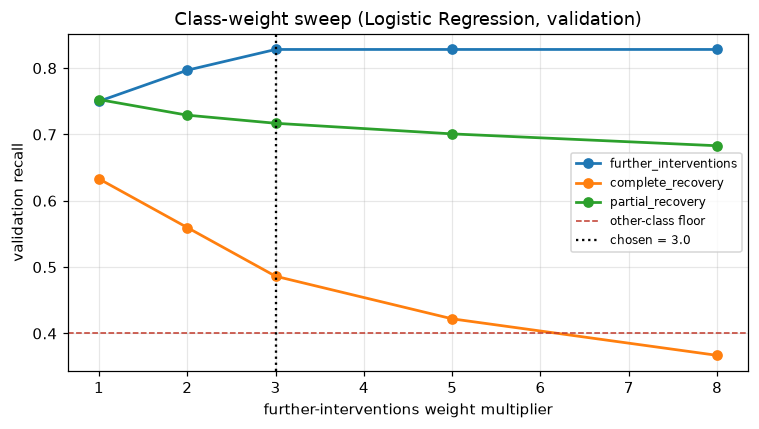

In [12]:
OTHER_CLASS_RECALL_FLOOR = 0.40
FI_MULTIPLIERS = [1, 2, 3, 5, 8]


def class_weights_for_multiplier(y, multiplier, boost_class="further interventions"):
    classes = sorted(y.unique())
    base = compute_class_weight("balanced", classes=np.array(classes), y=y)
    weights = dict(zip(classes, base))
    weights[boost_class] = weights[boost_class] * multiplier
    return weights


sweep_rows = []
for mult in FI_MULTIPLIERS:
    weights = class_weights_for_multiplier(y_train, mult)
    m = fit_model(BEST_MODEL, X_train_enc, y_train, params=best_params, weights=weights)
    pred = predict_model(BEST_MODEL, m, X_val_enc)

    labels = sorted(set(y_val) | set(pred))
    recalls = dict(zip(labels, recall_score(y_val, pred, labels=labels, average=None,
                                            zero_division=0)))
    sweep_rows.append({"fi_multiplier": mult,
                       "recall_further_interventions": recalls.get("further interventions", 0),
                       "recall_complete_recovery": recalls.get("complete recovery", 0),
                       "recall_partial_recovery": recalls.get("partial recovery", 0)})

sweep = pd.DataFrame(sweep_rows)
print(sweep.to_string(index=False, float_format="%.4f"))

valid = sweep[(sweep["recall_complete_recovery"] >= OTHER_CLASS_RECALL_FLOOR) &
             (sweep["recall_partial_recovery"] >= OTHER_CLASS_RECALL_FLOOR)]
if valid.empty:
    print(f"\nNo multiplier kept both other classes' recall >= {OTHER_CLASS_RECALL_FLOOR}.")
    winner = sweep.loc[sweep["recall_further_interventions"].idxmax()]
else:
    winner = valid.loc[valid["recall_further_interventions"].idxmax()]

FI_MULTIPLIER = winner["fi_multiplier"]
print(f"\nSelected multiplier: {FI_MULTIPLIER}")
print(f"  recall(FI)={winner['recall_further_interventions']:.3f}  "
      f"recall(CR)={winner['recall_complete_recovery']:.3f}  "
      f"recall(PR)={winner['recall_partial_recovery']:.3f}")

plt.figure(figsize=(7, 4))
for col in ["recall_further_interventions", "recall_complete_recovery", "recall_partial_recovery"]:
    plt.plot(sweep["fi_multiplier"], sweep[col], "o-", lw=1.8, label=col.replace("recall_", ""))
plt.axhline(OTHER_CLASS_RECALL_FLOOR, color="#c0392b", ls="--", lw=1, label="other-class floor")
plt.axvline(FI_MULTIPLIER, color="k", ls=":", lw=1.5, label=f"chosen = {FI_MULTIPLIER}")
plt.xlabel("further-interventions weight multiplier"); plt.ylabel("validation recall")
plt.title(f"Class-weight sweep ({BEST_MODEL}, validation)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(ARTIFACTS / "weight_sweep.png", bbox_inches="tight"); plt.show()

final_weights = class_weights_for_multiplier(y_train, FI_MULTIPLIER)
final_model = fit_model(BEST_MODEL, X_train_enc, y_train, params=best_params,
                        weights=final_weights)

## 12. Held-out evaluation — opened once

Feature set, model, hyperparameters, and class-weight balance were all chosen on train and
validation. The holdout is read here for the first and only time. Nothing below is re-tuned in
response to what it shows.

HELD-OUT RESULTS (first and only reading)
                       precision    recall  f1-score   support

    complete recovery      0.259     0.486     0.338       109
further interventions      0.186     0.766     0.300        64
     partial recovery      0.978     0.706     0.820      1063

             accuracy                          0.690      1236
            macro avg      0.474     0.653     0.486      1236
         weighted avg      0.873     0.690     0.751      1236

Per-class recall: {'complete recovery': np.float64(0.486), 'partial recovery': np.float64(0.706), 'further interventions': np.float64(0.766)}
F1 macro: 0.486


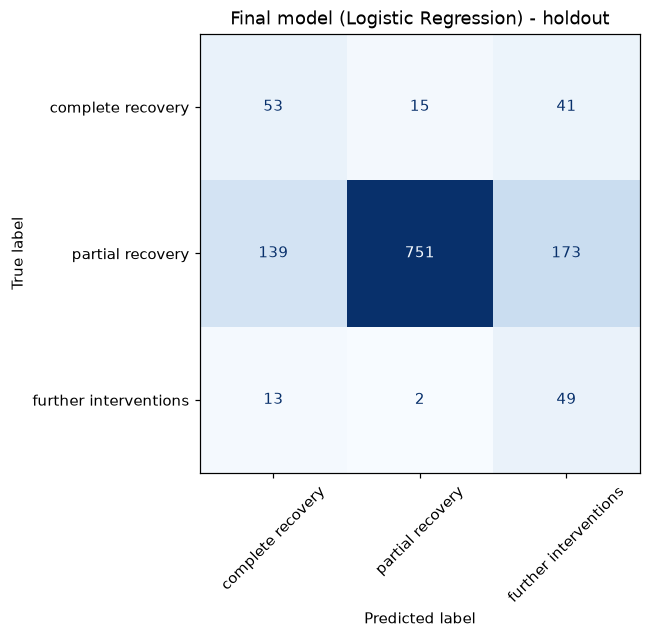

In [13]:
y_pred_hold = predict_model(BEST_MODEL, final_model, X_hold_enc)

print("=" * 58)
print("HELD-OUT RESULTS (first and only reading)")
print("=" * 58)
print(classification_report(y_hold, y_pred_hold, digits=3))

labels_order = ["complete recovery", "partial recovery", "further interventions"]
hold_recalls = dict(zip(labels_order, recall_score(y_hold, y_pred_hold, labels=labels_order,
                                                   average=None, zero_division=0)))
print("Per-class recall:", {k: round(v, 3) for k, v in hold_recalls.items()})
print(f"F1 macro: {f1_score(y_hold, y_pred_hold, average='macro'):.3f}")

cm = confusion_matrix(y_hold, y_pred_hold, labels=labels_order)
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(cm, display_labels=labels_order).plot(ax=ax, xticks_rotation=45,
                                                              colorbar=False, cmap="Blues")
plt.title(f"Final model ({BEST_MODEL}) - holdout"); ax.grid(False)
plt.tight_layout(); plt.savefig(ARTIFACTS / "holdout_confusion.png", bbox_inches="tight"); plt.show()

## 13. What the model pays attention to

**Permutation importance** on the holdout, not SHAP — consistent with the severity model. Each
feature is shuffled in turn and the drop in recall(further interventions) measured. Tree-internal
importances and SHAP on high-cardinality categoricals (`Site of Injury No1` has 43 levels) both
bias toward those features; permutation importance measures the effect on actual predictions
instead.

                          feature  importance    std
             Collision Force From      0.2687 0.0513
              Type of injury No 1      0.2000 0.0517
              Alcohol Consumption      0.1453 0.0252
Mode of Transport to the Hospital      0.0516 0.0328
        Transfer To Next Hospital      0.0406 0.0200
              Site of injury No 2      0.0234 0.0144
                Management Name 1      0.0031 0.0117
                              Age      0.0000 0.0000
                State of Transfer      0.0000 0.0000
               Investigation Done      0.0000 0.0171
                Approximate Speed     -0.0016 0.0084
                       total_days     -0.0016 0.0047
                   Road Condition     -0.0125 0.0182
               Site of Injury No1     -0.0141 0.0203
                Management Name 2     -0.0156 0.0232
              Type of Injury No 2     -0.0172 0.0283
                   Collision With     -0.0203 0.0186
                        Road Type     -0.0344 

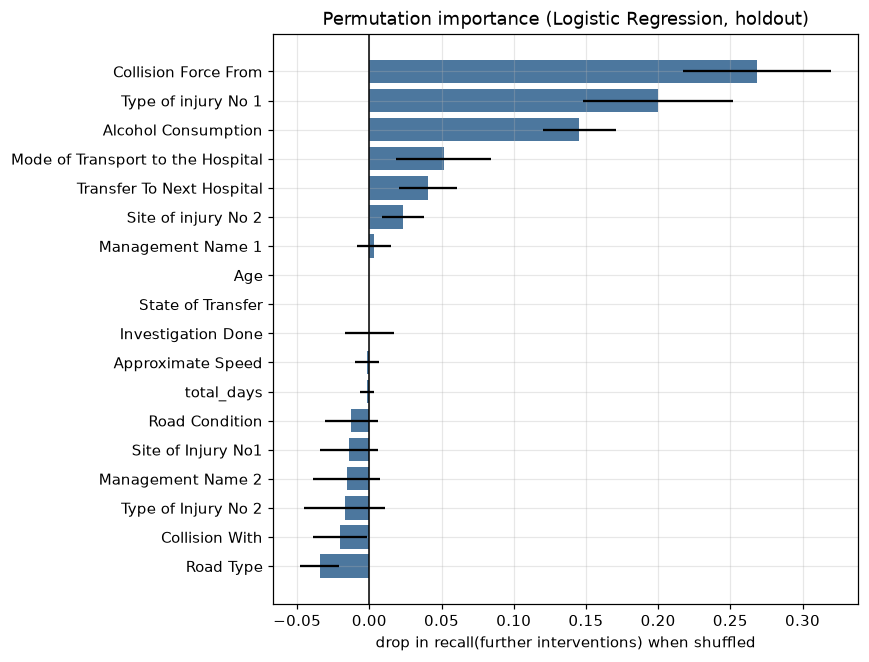

In [14]:
def score_fn(estimator, X, y):
    pred = predict_model(BEST_MODEL, estimator, X)
    return recall_further_interventions(y, pred)


perm = permutation_importance(final_model, X_hold_enc, y_hold, scoring=score_fn,
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)

importance = (pd.DataFrame({"feature": X_hold_enc.columns, "importance": perm.importances_mean,
                            "std": perm.importances_std})
              .sort_values("importance", ascending=False).reset_index(drop=True))
print(importance.to_string(index=False, float_format="%.4f"))

plt.figure(figsize=(8, max(4, 0.34 * len(importance))))
top = importance.iloc[::-1]
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="#2c5f8d", alpha=0.85)
plt.axvline(0, color="k", lw=1)
plt.xlabel("drop in recall(further interventions) when shuffled")
plt.title(f"Permutation importance ({BEST_MODEL}, holdout)")
plt.tight_layout(); plt.savefig(ARTIFACTS / "permutation_importance.png", bbox_inches="tight")
plt.show()

## 14. Confidence layer — derived, not assumed

The completeness floor is measured the same way as the severity model's: recall(further
interventions) is checked per completeness level on validation, and the floor sits at the lowest
level where the model still performs usefully.

In [15]:
MIN_USABLE_RECALL = 0.30

completeness_val = X_val.notna().sum(axis=1) / len(FEATURES)
p_val_pred = predict_model(BEST_MODEL, final_model, X_val_enc)

floor_rows = []
for level in sorted(completeness_val.unique()):
    at_level = completeness_val == level
    if at_level.sum() < 20:
        continue
    floor_rows.append({"completeness": level, "patients": int(at_level.sum()),
                       "recall_fi": recall_further_interventions(
                           y_val[at_level], p_val_pred[at_level])})

floors = pd.DataFrame(floor_rows).sort_values("completeness")
print(floors.to_string(index=False, float_format="%.3f"))

usable = floors.loc[floors["recall_fi"] >= MIN_USABLE_RECALL, "completeness"]
COMPLETENESS_FLOOR = float(usable.min()) if not usable.empty else 0.0
print(f"\nCompleteness floor: {COMPLETENESS_FLOOR:.2f} "
      f"({int(np.ceil(COMPLETENESS_FLOOR * len(FEATURES)))} of {len(FEATURES)} fields)")

 completeness  patients  recall_fi
        0.278        22      0.000
        0.333        37      0.000
        0.389        42      0.000
        0.556        40      0.000
        0.611        89      0.000
        0.667        43      0.000
        0.722        83      0.000
        0.778       110      0.500
        0.833       108      1.000
        0.889       257      0.846
        0.944       261      0.893
        1.000       124      0.875

Completeness floor: 0.78 (14 of 18 fields)


**Probability threshold for "low confidence"** is a stated judgement call, same as the
severity model's clinical-cost ratios — no amount of data alone settles it. Set at 0.5 (majority
vote in a 3-class problem carries less certainty than in binary, so a lower bar than the
severity model's implicit threshold is used deliberately).

In [16]:
LOW_CONF_PROB = 0.50

NURSE_LABELS = {
    "Age": "age", "Mode of Transport to the Hospital": "how they reached hospital",
    "Time Taken To Reach Hospital": "time taken to reach hospital", "Vehicle Type": "vehicle type",
    "Helmet Worn": "helmet worn", "Collision With": "what they collided with",
    "Site of Injury No1": "main injury site", "Type of injury No 1": "main injury type",
    "Site of injury No 2": "second injury site", "Type of Injury No 2": "second injury type",
    "Transfer To Next Hospital": "transferred to another hospital",
    "Treatment During Tranfer": "treatment during transfer", "State of Transfer": "transfer state",
    "Investigation Done": "investigation done", "Management Name 1": "primary management given",
    "Management Name 2": "secondary management given", "total_days": "total days in ward",
}


def predict_discharge_outcome(record: dict) -> dict:
    present = sum(1 for f in FEATURES if record.get(f) is not None and not pd.isna(record.get(f)))
    completeness = present / len(FEATURES)

    if completeness < COMPLETENESS_FLOOR:
        return {"prediction": None, "probability": None, "completeness": round(completeness, 3),
                "status": f"REFUSED - only {present} of {len(FEATURES)} fields recorded"}

    row = pd.DataFrame([{f: record.get(f) for f in FEATURES}])
    row = encode_ordinal(row, FEATURES)

    proba, classes = predict_proba_model(BEST_MODEL, final_model, row)
    proba = proba[0]
    pred_idx = int(np.argmax(proba))
    pred_label, pred_prob = classes[pred_idx], float(proba[pred_idx])

    status = "OK" if pred_prob >= LOW_CONF_PROB else "LOW CONFIDENCE"
    return {"prediction": pred_label, "probability": round(pred_prob, 3),
            "completeness": round(completeness, 3), "status": status}


print("Example - well-documented record:")
print(predict_discharge_outcome(X_hold.iloc[0].to_dict()))
print("\nExample - sparse record:")
print(predict_discharge_outcome({"Age": "20-29"}))

Example - well-documented record:
{'prediction': None, 'probability': None, 'completeness': 0.667, 'status': 'REFUSED - only 12 of 18 fields recorded'}

Example - sparse record:
{'prediction': None, 'probability': None, 'completeness': 0.056, 'status': 'REFUSED - only 1 of 18 fields recorded'}


## 15. Save artifacts

In [17]:
joblib.dump(final_model, ARTIFACTS / "discharge_outcome_model.joblib")

joblib.dump({"features": FEATURES, "cat_features": CAT_FEATURES, "num_features": NUM_FEATURES,
             "age_order": AGE_ORDER, "time_order": TIME_ORDER, "best_model_name": BEST_MODEL,
             "completeness_floor": COMPLETENESS_FLOOR, "low_conf_prob": LOW_CONF_PROB,
             "rare_maps": {k: list(v) for k, v in rare_maps.items()}},
            ARTIFACTS / "discharge_outcome_metadata.joblib")

summary = {
    "purpose": "Post-treatment prediction of discharge outcome (complete recovery / partial "
               "recovery / further interventions), intended for doctor use after treatment.",
    "split": {"train": len(y_train), "validation": len(y_val), "holdout": len(y_hold),
              "protocol": "all decisions on train/validation; holdout read once"},
    "target": {"classes": sorted(y_all.unique().tolist()),
               "prevalence": y_all.value_counts(normalize=True).round(4).to_dict()},
    "eligibility_audit": audit.value_counts().to_dict(),
    "features": {"candidates": len(CANDIDATE_FEATURES), "selection_rule": winner if isinstance(winner, str) else "",
                 "final": FEATURES, "dropped": DROPPED},
    "model_comparison": results.to_dict(orient="records"),
    "model": {"family": BEST_MODEL, "best_params": {k: str(v) for k, v in best_params.items()},
              "fi_weight_multiplier": float(FI_MULTIPLIER),
              "other_class_recall_floor": OTHER_CLASS_RECALL_FLOOR},
    "holdout_recall_per_class": {k: round(float(v), 4) for k, v in hold_recalls.items()},
    "holdout_f1_macro": round(float(f1_score(y_hold, y_pred_hold, average="macro")), 4),
    "completeness_floor": round(COMPLETENESS_FLOOR, 3),
    "low_confidence_probability_threshold": LOW_CONF_PROB,
    "top_features": importance.head(8)["feature"].tolist(),
}
with open(ARTIFACTS / "model_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

screening.to_csv(ARTIFACTS / "feature_screening.csv", index=False)
importance.to_csv(ARTIFACTS / "permutation_importance.csv", index=False)
results.to_csv(ARTIFACTS / "model_comparison.csv", index=False)

print(json.dumps(summary, indent=2))
print(f"\nSaved to {ARTIFACTS.resolve()}")

{
  "purpose": "Post-treatment prediction of discharge outcome (complete recovery / partial recovery / further interventions), intended for doctor use after treatment.",
  "split": {
    "train": 3705,
    "validation": 1236,
    "holdout": 1236,
    "protocol": "all decisions on train/validation; holdout read once"
  },
  "target": {
    "classes": [
      "complete recovery",
      "further interventions",
      "partial recovery"
    ],
    "prevalence": {
      "partial recovery": 0.8603,
      "complete recovery": 0.0882,
      "further interventions": 0.0515
    }
  },
  "eligibility_audit": {
    "BOOKKEEPING": 65,
    "POST_ARRIVAL_ELIGIBLE": 44,
    "EXCLUDED_ETHICAL": 16,
    "ADMIN": 4,
    "TARGET": 1
  },
  "features": {
    "candidates": 25,
    "selection_rule": "",
    "final": [
      "Age",
      "Mode of Transport to the Hospital",
      "Collision With",
      "Approximate Speed",
      "Road Type",
      "Road Condition",
      "Collision Force From",
      "Alcoho

## 16. Limitations

**1. Severe class imbalance limits the ceiling.** `further interventions` is 5.1% of patients. No
amount of class weighting manufactures information that isn't there — it only reweights what
mistakes cost during training.

**2. This is a screening aid, not a discharge decision.** A doctor's clinical judgement should
never be overridden by this model. It exists to flag cases worth a second look before finalising
discharge.

**3. The other-class recall floor (0.40) and low-confidence threshold (0.50) are judgement
calls.** Reasoned, sensitivity-tested against alternative multipliers in Section 11, but not
something the data determines on its own — a hospital adopting this tool should treat both as
tunable.

**4. `total_days` and length-of-stay features share information with the severity model's
excluded confound.** Here that's legitimate, since this model runs post-treatment and length of
stay is a known fact by then — but it means this model's `total_days` signal partly reflects
resource use at this specific hospital, same underlying pattern the severity model excluded for
a different reason (there it was measured pre-treatment and confounded; here it's measured
post-treatment and legitimate).

**5. Single-setting data.** One hospital network, northern Sri Lanka — same limitation as every
other model in this project.

**6. Not validated prospectively.** Retrospective evaluation only.